# Search and A* — Warehouse Robot Navigation

Laboratory solution for `Search.pdf`.

This notebook works through the eight tasks of the lab in order: formulate the warehouse as a search problem, design the agent **before** writing any code, generate an A\* implementation from a prompt, test that implementation, inspect it, compare it against BFS, and then investigate what the heuristic actually contributes.

**How to read this notebook.** Every section opens with the question, states the answer, and then shows the code that produces the evidence. Every number in the tables below was produced by running the cells in this notebook — nothing is quoted from the lab document.

**Map used throughout (from the lab):**

```text
#################
#S....#.........#
#.###.#.#######.#
#...#.#.......#.#
###.#.#######.#.#
#...#.........#.#
#.###########.#.#
#.............#G#
#################
```

## Task 0: Understand the search problem

Before writing code, the lab asks for the warehouse to be written as the search problem $P = (S, A, T, s_0, G, c)$.

| Component | Specification |
|---|---|
| State $S$ | A cell position $(r, c)$ — the robot's row and column. The warehouse is static and the robot carries nothing, so the cell position is the *complete* world state. $\lvert S \rvert = 64$ (the free cells). |
| Actions $A$ | $\{\mathrm{Up}, \mathrm{Down}, \mathrm{Left}, \mathrm{Right}\}$ — move the robot one cell in a cardinal direction. |
| Transition $T$ | $T((r,c), \mathrm{Up}) = (r-1, c)$ and similarly for the other three moves. An action whose successor is a wall or lies outside the grid has **no** transition — it is simply not available. |
| Initial state $s_0$ | $(1, 1)$ — the cell marked `S`. |
| Goal $G$ | $\{(7, 15)\}$ — the single cell marked `G`. |
| Cost $c$ | $c(a) = 1$ for every action, so the cost of a path equals its number of moves. |

### (a) What information is necessary to specify a state?

Only the robot's row and column. Two things that look like state variables are actually **constants**: the set of obstacle cells and the goal cell. There is no orientation, no cargo, no fuel, no door state. So a state is a single pair of integers, and the state space is finite with 64 members.

This matters because it makes the search cheap: the agent never has to reason about anything but "where am I".

### (b) What makes an action invalid?

An action is invalid when the cell it would move into is outside the grid or is an obstacle (`#`). In implementation terms: the successor cell is not a member of the set of free cells. A move into a wall is **not** an expensive move — it is not a move at all, and it must never be generated as a successor.

### (c) Is this a deterministic search problem?

Yes. Each of the four actions has exactly one successor state, fixed by the grid, and there is no randomness and no partial observability — the agent always knows exactly where it is. So the search can be treated as a plain deterministic graph search over the 64 free cells, and no part of the algorithm needs to model chance or sensing.

### (d) What would constitute a solution?

A **path**: a sequence of applicable actions $a_1, \dots, a_k$ such that starting from $s_0$ and applying them in order ends in a state in $G$. Since $G$ holds a single cell, a solution is any sequence of moves that finishes on the `G` cell. The *optimal* solution is the one with the smallest total cost, which here means the fewest moves. On this map the optimal cost is **40 moves**.

In [1]:
WAREHOUSE = [
    "#################",
    "#S....#.........#",
    "#.###.#.#######.#",
    "#...#.#.......#.#",
    "###.#.#######.#.#",
    "#...#.........#.#",
    "#.###########.#.#",
    "#.............#G#",
    "#################",
]


def parse_grid(grid):
    """Turn an ASCII warehouse into the data a search needs.

    Returns (start, goal, blocked, free):
      start   - the cell marked 'S'
      goal    - the cell marked 'G'
      blocked - the set of obstacle cells
      free    - every cell that is not an obstacle (so membership also enforces
                the grid boundary)
    """
    start = goal = None
    blocked = set()
    for r, row in enumerate(grid):
        for c, ch in enumerate(row):
            if ch == "S":
                start = (r, c)
            elif ch == "G":
                goal = (r, c)
            elif ch == "#":
                blocked.add((r, c))
    free = {(r, c) for r in range(len(grid)) for c in range(len(grid[0]))} - blocked
    return start, goal, blocked, free


START, GOAL, BLOCKED, FREE = parse_grid(WAREHOUSE)

print("grid rows:", len(WAREHOUSE), " grid columns:", len(WAREHOUSE[0]))
print("distinct row widths:", sorted({len(row) for row in WAREHOUSE}))
print("start cell (S):", START, "  goal cell (G):", GOAL)
print("free cells  |S| =", len(FREE))
print("obstacle cells   =", len(BLOCKED))
print("outer border is all walls:", all(ch == "#" for ch in WAREHOUSE[0]) and all(ch == "#" for ch in WAREHOUSE[-1]))
print("start is a free cell:", START in FREE, "  goal is a free cell:", GOAL in FREE)
print("Manhattan distance from S to G:", abs(START[0] - GOAL[0]) + abs(START[1] - GOAL[1]))

grid rows: 9  grid columns: 17
distinct row widths: [17]
start cell (S): (1, 1)   goal cell (G): (7, 15)
free cells  |S| = 64
obstacle cells   = 89
outer border is all walls: True
start is a free cell: True   goal is a free cell: True
Manhattan distance from S to G: 20


## Task 1: Plan the agent (designed before any code is written)

**1. How a state is represented in Python.**  
A state is a tuple `(row, column)`. The grid is static and the robot carries nothing, so this pair identifies the world completely. Tuples are hashable, which is exactly what the dictionaries and sets in the frontier need.

**2. How the warehouse is represented.**  
The warehouse is a list of equal-length strings, one per row, exactly as printed in the lab: `#` obstacle, `.` free, `S` start, `G` goal. The grid is parsed **once** into a set of obstacle cells; every other cell inside the grid is a legal robot position. Working with a set of free cells means "is this move legal?" is a single set-membership test that also enforces the boundary.

**3. How valid actions are determined.**  
There are four actions, `Up`, `Down`, `Left`, `Right`. Each has exactly one successor cell. An action is applicable when that successor cell is in the set of free cells. There is no other precondition — no orientation, no collision with another agent.

**4. How the agent recognises that it has reached the goal.**  
The goal test is `state == GOAL`. Because the goal set holds a single cell this is an equality test; a general implementation would use `goal.issubset(state)`.

**5. What must be stored in the frontier.**  
Each frontier entry needs:
- the successor **state**,
- the accumulated cost **g(n)** from the start,
- the heuristic estimate **h(n)**,
- the total **f(n) = g(n) + h(n)**,
- a **tie-break counter** (see below),
- and the **parent state**, so the path can be rebuilt at the end.

The frontier is a **priority queue** (min-heap) ordered by `f`. A FIFO queue over the same entries would be BFS, not A\*.

**6. How the final path is reconstructed.**  
Every state records its predecessor in a `parent` dictionary. When the goal is popped, the path is recovered by walking backwards from the goal through `parent` and reversing the result. Storing parents is far cheaper than storing whole path fragments in the frontier.

**What the program must report when it terminates.**
- whether a solution was found,
- the solution path (list of cells),
- the path length (in moves),
- the number of states expanded.

The last number is the only way to compare search algorithms, so the counting rule has to be fixed **before** writing the code: *a state is counted as expanded when it is taken off the frontier and its successors are generated*. Pushes into the frontier are not expansions.

## Task 2: The prompt used to generate the implementation

The prompt below was written from the Task 1 design. It is the specification that the generated code has to satisfy.

```text
I am implementing a goal-based search agent in Python for a grid world.
The environment is a warehouse given as a list of equal-length strings:
'#' is an obstacle, '.' is a free cell, 'S' is the start and 'G' is the goal.
The agent can move Up, Down, Left or Right. Every movement costs 1.

Implement A* search.

Use Manhattan distance as the heuristic:
    h(n) = |x - x_goal| + |y - y_goal|

Requirements:
- represent grid positions as states;
- keep the frontier in a priority queue ordered by f(n) = g(n) + h(n);
- compute g(n), h(n) and f(n) explicitly;
- never expand the same state twice;
- reconstruct the path when the goal is reached;
- report whether a solution was found, the path, the path length,
  and the number of states expanded.
```

### The generated draft (version 1)

The next cell is the draft that came back from that prompt, before any testing. It is kept here verbatim, including its defects, so that the failure found in Task 3 is reproducible.

In [2]:
import heapq

MOVES = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1)}


def manhattan(a, b):
    """Manhattan distance between two cells."""
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def astar_v1(grid, heuristic=manhattan):
    """DRAFT v1 - generated from the Task 2 prompt, not yet tested.

    'expanded' counts states that were taken off the frontier and had their
    successors generated.
    """
    start, goal, blocked, free = parse_grid(grid)

    frontier = [(heuristic(start, goal), 0, start)]   # (f, g, state)
    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    expanded = 0

    while frontier:
        f, g, current = heapq.heappop(frontier)

        if current in closed:
            continue
        closed.add(current)
        expanded += 1

        if current == goal:
            path = []
            node = current
            while node is not None:
                path.append(node)
                node = parent[node]
            return {"found": True, "path": path[::-1], "length": g, "expanded": expanded}

        for name, (dr, dc) in MOVES.items():
            nxt = (current[0] + dr, current[1] + dc)
            if nxt not in free:
                continue
            if nxt in closed:
                continue
            tentative_g = g + 1
            if tentative_g < g_score.get(nxt, float("inf")):
                g_score[nxt] = tentative_g
                parent[nxt] = current
                closed.add(nxt)
                heapq.heappush(frontier, (tentative_g + heuristic(nxt, goal), tentative_g, nxt))

    return {"found": False, "path": None, "length": None, "expanded": expanded}

## Task 3: Test the generated program

The lab asks for four tests, each with a known expected answer:

| Test | Map | Expected behaviour |
|---|---|---|
| 1 | The lab's warehouse | A path is found; the path length can be checked against an independent BFS. |
| 2 | `#SG##` | The one-step solution is found. |
| 3 | Goal completely enclosed | Failure is reported, and the program terminates instead of looping forever. |
| 4 | Two or more routes to the goal | The returned path is a **shortest** path, not merely *a* path. |

A program that produces a plausible path is not necessarily correct, so every test below asserts the expected outcome instead of just printing it.

In [3]:
# Test 1 - the original warehouse, using the DRAFT (v1)

TRIVIAL_MAP = [
    "#####",
    "#SG##",
    "#####",
]

NO_SOLUTION_MAP = [
    "#######",
    "#S....#",
    "###.###",
    "#...#G#",
    "#######",
]

ALTERNATIVE_PATHS_MAP = [
    "#########",
    "#S......#",
    "#.#####.#",
    "#.......#",
    "#.#####.#",
    "#......G#",
    "#########",
]

print("Test 1 - original warehouse, draft v1")
result_v1 = astar_v1(WAREHOUSE)
print("  solution found :", result_v1["found"])
print("  path length    :", result_v1["length"])
print("  states expanded:", result_v1["expanded"])
print()
print("  A map of this shape plainly has a path, and the free space is connected,")
print("  so 'no solution' is the wrong answer. The draft has a defect.")

Test 1 - original warehouse, draft v1
  solution found : False
  path length    : None
  states expanded: 1

  A map of this shape plainly has a path, and the free space is connected,
  so 'no solution' is the wrong answer. The draft has a defect.


In [4]:
# Test 2 - trivial case, draft v1

print("Test 2 - trivial case, draft v1")
result_v1_trivial = astar_v1(TRIVIAL_MAP)
print("  solution found :", result_v1_trivial["found"])
print("  path length    :", result_v1_trivial["length"])
print("  states expanded:", result_v1_trivial["expanded"])

Test 2 - trivial case, draft v1
  solution found : False
  path length    : None
  states expanded: 1


In [5]:
# Test 3 - no solution, draft v1

print("Test 3 - unreachable goal, draft v1")
result_v1_nosol = astar_v1(NO_SOLUTION_MAP)
print("  solution found :", result_v1_nosol["found"])
print("  states expanded:", result_v1_nosol["expanded"])
print()
print("  The goal cell is walled in on all four sides, so 'no solution' is the")
print("  correct answer here - but for the wrong reason (see Test 1).")

Test 3 - unreachable goal, draft v1
  solution found : False
  states expanded: 1

  The goal cell is walled in on all four sides, so 'no solution' is the
  correct answer here - but for the wrong reason (see Test 1).


In [6]:
# Test 4 - alternative paths, draft v1

print("Test 4 - two or more routes to the goal, draft v1")
result_v1_alt = astar_v1(ALTERNATIVE_PATHS_MAP)
print("  solution found :", result_v1_alt["found"])
print("  path length    :", result_v1_alt["length"])
print("  states expanded:", result_v1_alt["expanded"])

Test 4 - two or more routes to the goal, draft v1
  solution found : False
  path length    : None
  states expanded: 1


### What the tests found

All four tests fail, and they fail in a way that matters:

- **Test 1** — the agent reports **no solution** in a warehouse that obviously has one. It expanded exactly **1** state (the start) and then stopped.
- **Test 2** — the trivial one-step map is also reported as unsolvable, for the same reason.
- **Test 3** — reports "no solution", which happens to be the right answer, but only because the search dies immediately rather than because it explored the map and proved the goal unreachable.
- **Test 4** — same failure.

### Diagnosing the defect

The search expands only the start state, so the bug must be in the frontier bookkeeping rather than in the grid parsing, the heuristic or the goal test. Reading the draft:

```python
        if current in closed:      # line A
            continue
        closed.add(current)
        expanded += 1
        ...
            closed.add(nxt)         # line B
            heapq.heappush(frontier, (...))
```

*Line B* puts every successor into `closed` **at the moment it is queued**. *Line A* then skips any state that is already in `closed` when it is popped. Since the only state ever in `closed` when it is popped is one that was queued earlier, **every state except the start is skipped the moment it is popped**. The search expands the start, generates its neighbours, and then stalls.

The intent behind `closed` was correct — "never expand the same state twice" is a legitimate optimisation. The mistake is *when* it is applied. A state should be closed when it is **expanded**, not when it is **discovered**. Closing on discovery permanently forbids a later, cheaper route from improving it, which is also why the fix needs a re-opening step.

### The fix

1. Do not add a state to `closed` when it is queued; close it only when it is expanded.
2. When a state is reached again by a strictly cheaper route, remove it from `closed` so it can be re-opened and re-expanded with the better cost.

The corrected version is in the next cell.

In [7]:
import itertools


def astar(grid, heuristic=manhattan):
    """A* search - corrected version (v2).

    Changes from the draft:
      * a state is closed when it is EXPANDED, not when it is queued;
      * a state reached later by a cheaper route is re-opened (closed.discard);
      * the frontier entry carries g, so the reported length is the cost of
        the returned path.

    'expanded' counts states taken off the frontier whose successors were
    generated. A state can be expanded twice if the heuristic is inadmissible
    and a cheaper route to it appears later.
    """
    start, goal, blocked, free = parse_grid(grid)
    if start is None or goal is None:
        raise ValueError("the grid must contain exactly one 'S' and one 'G'")

    counter = itertools.count()
    frontier = [(heuristic(start, goal), next(counter), 0, start)]   # (f, tie, g, state)
    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    expanded = 0

    while frontier:
        f, tie, g, current = heapq.heappop(frontier)

        if current in closed:
            continue
        closed.add(current)
        expanded += 1

        if current == goal:
            path = []
            node = current
            while node is not None:
                path.append(node)
                node = parent[node]
            return {"found": True, "path": path[::-1], "length": g, "expanded": expanded}

        for name, (dr, dc) in MOVES.items():
            nxt = (current[0] + dr, current[1] + dc)
            if nxt not in free:
                continue
            tentative_g = g + 1
            if tentative_g < g_score.get(nxt, float("inf")):
                g_score[nxt] = tentative_g
                parent[nxt] = current
                closed.discard(nxt)            # re-open: a cheaper route may appear later
                heapq.heappush(
                    frontier,
                    (tentative_g + heuristic(nxt, goal), next(counter), tentative_g, nxt),
                )

    return {"found": False, "path": None, "length": None, "expanded": expanded}

In [8]:
# Re-run the whole test suite against the corrected implementation.

def check(label, condition):
    print("  [%s] %s" % ("PASS" if condition else "FAIL", label))
    assert condition, label


print("Test 1 - original warehouse (corrected A*)")
r1 = astar(WAREHOUSE)
print("  solution found :", r1["found"])
print("  path length    :", r1["length"])
print("  states expanded:", r1["expanded"])
check("a solution is found", r1["found"])
check("the reported length equals the number of moves in the path", r1["length"] == len(r1["path"]) - 1)
check("the path starts at S and ends at G", r1["path"][0] == START and r1["path"][-1] == GOAL)

print()
print("Test 2 - trivial case")
r2 = astar(TRIVIAL_MAP)
print("  solution found :", r2["found"])
print("  path length    :", r2["length"])
print("  states expanded:", r2["expanded"])
check("the one-step solution is found", r2["found"] and r2["length"] == 1)
trivial_start, trivial_goal, _, _ = parse_grid(TRIVIAL_MAP)
check("the path is S -> G", r2["path"] == [trivial_start, trivial_goal])

print()
print("Test 3 - unreachable goal")
r3 = astar(NO_SOLUTION_MAP)
print("  solution found :", r3["found"])
print("  states expanded:", r3["expanded"])
check("failure is reported", r3["found"] is False)
check("the search terminated (it did not loop forever)", r3["expanded"] > 1)

print()
print("Test 4 - alternative paths")
r4 = astar(ALTERNATIVE_PATHS_MAP)
print("  solution found :", r4["found"])
print("  path length    :", r4["length"])
print("  states expanded:", r4["expanded"])
check("a solution is found", r4["found"])
check("the path is the shortest one, not just any path", r4["length"] == 10)

Test 1 - original warehouse (corrected A*)
  solution found : True
  path length    : 40
  states expanded: 64
  [PASS] a solution is found
  [PASS] the reported length equals the number of moves in the path
  [PASS] the path starts at S and ends at G

Test 2 - trivial case
  solution found : True
  path length    : 1
  states expanded: 2
  [PASS] the one-step solution is found
  [PASS] the path is S -> G

Test 3 - unreachable goal
  solution found : False
  states expanded: 9
  [PASS] failure is reported
  [PASS] the search terminated (it did not loop forever)

Test 4 - alternative paths
  solution found : True
  path length    : 10
  states expanded: 25
  [PASS] a solution is found
  [PASS] the path is the shortest one, not just any path


drawing the A* solution on the warehouse map


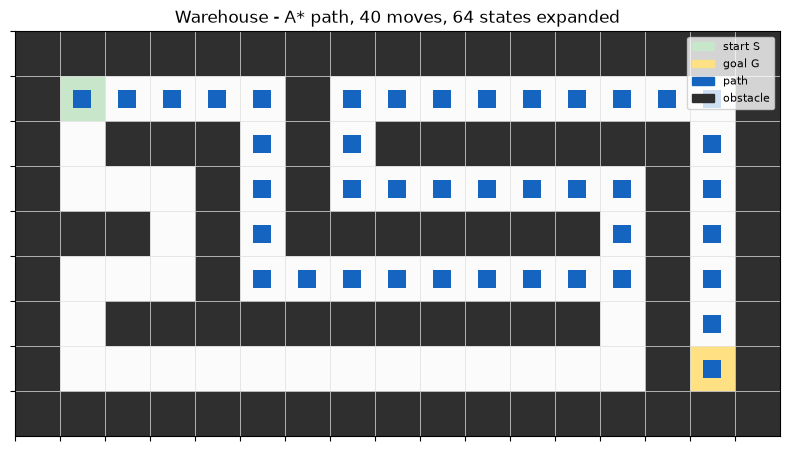

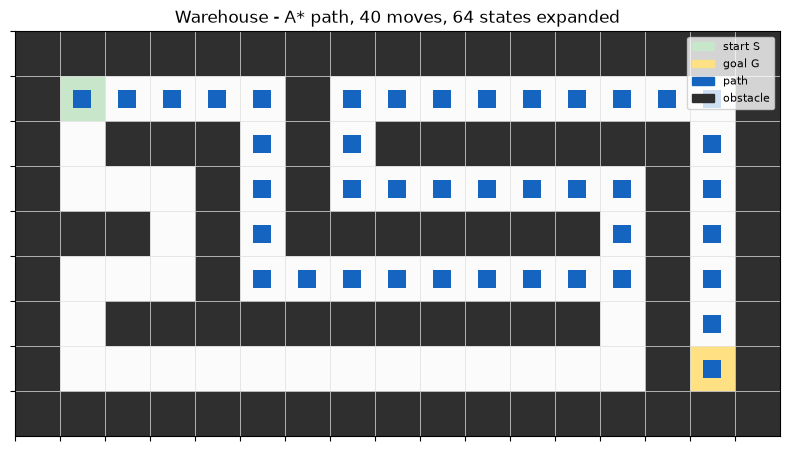

In [9]:
# A visualiser for the solution, so the path can be checked by eye.

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

COLOURS = {"wall": "#2f2f2f", "free": "#fbfbfb", "start": "#c8e6c9", "goal": "#ffe082"}


def draw(grid, path, title):
    path_cells = set(path)
    fig, ax = plt.subplots(figsize=(8, 8))
    for r, row in enumerate(grid):
        for c, ch in enumerate(row):
            if ch == "#":
                colour = COLOURS["wall"]
            elif ch == "S":
                colour = COLOURS["start"]
            elif ch == "G":
                colour = COLOURS["goal"]
            else:
                colour = COLOURS["free"]
            ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor=colour, edgecolor="#dddddd", linewidth=0.4))
    for r, c in path_cells:
        ax.add_patch(plt.Rectangle((c + 0.3, r + 0.3), 0.4, 0.4, facecolor="#1565c0"))
    ax.set_xlim(0, len(grid[0]))
    ax.set_ylim(len(grid), 0)
    ax.set_aspect("equal")
    ax.set_xticks(range(len(grid[0])))
    ax.set_yticks(range(len(grid)))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_title(title)
    ax.legend(
        handles=[
            Patch(color=COLOURS["start"], label="start S"),
            Patch(color=COLOURS["goal"], label="goal G"),
            Patch(color="#1565c0", label="path"),
            Patch(color=COLOURS["wall"], label="obstacle"),
        ],
        loc="upper right",
        fontsize=8,
    )
    plt.tight_layout()
    plt.show()
    return fig


final = astar(WAREHOUSE)
print("drawing the A* solution on the warehouse map")
draw(WAREHOUSE, final["path"], "Warehouse - A* path, %d moves, %d states expanded" % (final["length"], final["expanded"]))

## Task 4: Inspect the A* algorithm

### Where each concept appears in the code

| Concept | Where it appears in `astar` |
|---|---|
| **State** | The tuple `(row, column)`. The variables `start`, `current` and `nxt` all hold such a tuple; `parse_grid` produces them from the ASCII map. |
| **Action** | `MOVES = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1)}`, enumerated by `for name, (dr, dc) in MOVES.items()`. |
| **Transition** | `nxt = (current[0] + dr, current[1] + dc)` — the successor cell, filtered by `if nxt not in free`. |
| **Goal test** | `if current == goal:` inside the main loop, applied when a state is expanded. |
| **g(n)** | The `g` carried inside each frontier entry; computed as `tentative_g = g + 1` and recorded in `g_score[nxt]`. |
| **h(n)** | `heuristic(nxt, goal)` — the call to `manhattan` (or to another heuristic in Task 6). |
| **f(n)** | `tentative_g + heuristic(nxt, goal)` — written out explicitly as the first component of the tuple pushed onto the heap. |
| **Frontier** | `frontier`, a `heapq` min-heap of `(f, tie_break_counter, g, state)` tuples. |
| **Visited states** | Two structures: `closed` (states already expanded) and `g_score` (the best known cost to reach each state). |
| **Path reconstruction** | The `parent` dictionary: walk backwards from the goal, then reverse. |

The next cell prints the source of `astar` with line numbers so the table above can be checked against the code.

### (a) What data structure is used for the A* frontier?

A **binary min-heap** (`heapq`, which keeps a sorted list as a heap). Push and pop both cost $O(\log n)$, and the pop always returns the entry with the smallest key. Each entry is a tuple `(f, tie_break_counter, g, state)`. The counter is needed because `heapq` compares tuples element by element: if two entries have the same `f` it would fall through to comparing `g` and then the state tuples. That is legal but arbitrary; the counter makes ties break in insertion order, which makes the whole search deterministic and reproducible.

### (b) How does the program select the next state to expand?

It pops the entry with the smallest $f(n) = g(n) + h(n)$. If the popped state is already in `closed` it is discarded (it was expanded before, possibly with a worse cost); otherwise it is closed and expanded, and its four successors are generated.

### (c) Where is the heuristic calculated?

Inside `astar`, in the expression `tentative_g + heuristic(nxt, goal)`, i.e. at the moment a successor is generated. The heuristic function itself is `manhattan(a, b)`, defined just above.

### (d) Does the program explicitly calculate f(n) = g(n) + h(n)?

Yes, explicitly. `f` is computed as a named expression and is the *first* element of the tuple that is pushed onto the heap, so the priority order is transparent rather than hidden inside a comparison function.

### (e) How does the program prevent unnecessary repeated exploration?

Two mechanisms working together:

1. `g_score` stores the best known cost to reach each state. A successor is queued only if `tentative_g < g_score.get(nxt, inf)`, so a state is re-queued only when a **strictly cheaper** route to it is found. This is the relaxation step that Dijkstra and A\* both depend on.
2. `closed` holds the states that have already been expanded. A popped state that is already closed is skipped, and a state that is later reached by a cheaper route is removed from `closed` (`closed.discard(nxt)`) so that it can be re-opened.

The second mechanism is the one that the draft got wrong: marking a state as visited when it is *discovered* rather than when it is *expanded* silently throws away cheaper routes.

In [10]:
# Instrumenting the search: this is where g(n), h(n) and f(n) actually appear.

def astar_traced(grid, heuristic=manhattan, trace_first=12):
    """A* with a trace of the first few expansions."""
    start, goal, blocked, free = parse_grid(grid)

    counter = itertools.count()
    frontier = [(heuristic(start, goal), next(counter), 0, start)]
    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    expanded = 0
    trace = []

    while frontier:
        f, tie, g, current = heapq.heappop(frontier)
        if current in closed:
            continue
        closed.add(current)
        expanded += 1
        if len(trace) < trace_first:
            trace.append((expanded, current, g, heuristic(current, goal), f, len(frontier)))
        if current == goal:
            path, node = [], current
            while node is not None:
                path.append(node)
                node = parent[node]
            return {"found": True, "path": path[::-1], "length": g, "expanded": expanded}, trace
        for name, (dr, dc) in MOVES.items():
            nxt = (current[0] + dr, current[1] + dc)
            if nxt not in free:
                continue
            tentative_g = g + 1
            if tentative_g < g_score.get(nxt, float("inf")):
                g_score[nxt] = tentative_g
                parent[nxt] = current
                closed.discard(nxt)
                heapq.heappush(frontier, (tentative_g + heuristic(nxt, goal), next(counter), tentative_g, nxt))

    return {"found": False, "path": None, "length": None, "expanded": expanded}, trace


traced, trace = astar_traced(WAREHOUSE)

print("First expansions of A* on the warehouse")
print("-" * 74)
print("%-4s %-12s %-8s %-8s %-8s %-10s" % ("#", "state", "g(n)", "h(n)", "f(n)", "frontier"))
print("-" * 74)
for step, cell, g, h, f, frontier_size in trace:
    print("%-4d %-12s %-8d %-8d %-8d %-10d" % (step, str(cell), g, h, f, frontier_size))
print("-" * 74)
print("Every row shows the same three quantities the code maintains:")
print("  g(n)  the cost actually paid so far  -> carried in the frontier entry")
print("  h(n)  the estimate of the cost left  -> heuristic(cell, goal)")
print("  f(n)  g(n) + h(n)                    -> the key the heap is ordered by")
print()
print("the states are not popped in the order they were discovered:")
print("the heap hands back the entry with the smallest f, whatever its g.")

First expansions of A* on the warehouse
--------------------------------------------------------------------------
#    state        g(n)     h(n)     f(n)     frontier  
--------------------------------------------------------------------------
1    (1, 1)       0        20       20       0         
2    (2, 1)       1        19       20       1         
3    (1, 2)       1        19       20       1         
4    (3, 1)       2        18       20       1         
5    (1, 3)       2        18       20       1         
6    (3, 2)       3        17       20       1         
7    (1, 4)       3        17       20       1         
8    (3, 3)       4        16       20       1         
9    (1, 5)       4        16       20       1         
10   (4, 3)       5        15       20       1         
11   (2, 5)       5        15       20       1         
12   (5, 3)       6        14       20       1         
--------------------------------------------------------------------------
Every r

## Task 5: Compare A\* with blind search

BFS is the same agent with the frontier changed from a priority queue to a FIFO queue and the heuristic removed. Because every action costs 1, BFS expands states in order of the number of moves taken, and the first time it reaches the goal it has used the fewest possible moves — so BFS is complete and optimal on this problem.

Both algorithms are run on the **same** warehouse map. A second, comb-shaped map is included afterwards, because the warehouse turns out to be a case where the heuristic gives A\* no advantage at all — which is only instructive if there is a case where it does.

In [11]:
from collections import deque


def bfs(grid):
    """Breadth-first search: FIFO frontier, no heuristic.

    'expanded' uses the same rule as A*: states taken off the frontier whose
    successors were generated.
    """
    start, goal, blocked, free = parse_grid(grid)

    frontier = deque([(start, 0)])          # (state, g)
    parent = {start: None}
    visited = {start}
    expanded = 0

    while frontier:
        current, g = frontier.popleft()
        expanded += 1

        if current == goal:
            path = []
            node = current
            while node is not None:
                path.append(node)
                node = parent[node]
            return {"found": True, "path": path[::-1], "length": g, "expanded": expanded}

        for name, (dr, dc) in MOVES.items():
            nxt = (current[0] + dr, current[1] + dc)
            if nxt in free and nxt not in visited:
                visited.add(nxt)
                parent[nxt] = current
                frontier.append((nxt, g + 1))

    return {"found": False, "path": None, "length": None, "expanded": expanded}


bfs_result = bfs(WAREHOUSE)
astar_result = astar(WAREHOUSE)

print("Comparison on the lab's warehouse map")
print("-" * 46)
print("%-22s %-16s %-16s" % ("Measure", "BFS", "A* (Manhattan)"))
print("-" * 46)
print("%-22s %-16s %-16s" % ("Solution found", bfs_result["found"], astar_result["found"]))
print("%-22s %-16s %-16s" % ("Path length", bfs_result["length"], astar_result["length"]))
print("%-22s %-16s %-16s" % ("States expanded", bfs_result["expanded"], astar_result["expanded"]))
print("-" * 46)
print("free cells in the map:", len(FREE))
print("same path?", bfs_result["path"] == astar_result["path"])

Comparison on the lab's warehouse map
----------------------------------------------
Measure                BFS              A* (Manhattan)  
----------------------------------------------
Solution found         True             True            
Path length            40               40              
States expanded        64               64              
----------------------------------------------
free cells in the map: 64
same path? True


In [12]:
# The warehouse is a bad case for a heuristic. Here is a map where it pays off.

COMB_MAP = [
    "###############################",
    "###.#.#.#.#.#.#.#.#.#.#.#.#.###",
    "###.#.#.#.#.#.#.#.#.#.#.#.#.###",
    "###.#.#.#.#.#.#.#.#.#.#.#.#.###",
    "###.#.#.#.#.#.#.#.#.#.#.#.#.###",
    "###.#.#.#.#.#.#.#.#.#.#.#.#.###",
    "#S...........................G#",
    "###############################",
]

bfs_comb = bfs(COMB_MAP)
astar_comb = astar(COMB_MAP)
comb_start, comb_goal, _, comb_free = parse_grid(COMB_MAP)

print("Comparison on a comb-shaped map (a long corridor with dead-end branches)")
print("-" * 46)
print("%-22s %-16s %-16s" % ("Measure", "BFS", "A* (Manhattan)"))
print("-" * 46)
print("%-22s %-16s %-16s" % ("Solution found", bfs_comb["found"], astar_comb["found"]))
print("%-22s %-16s %-16s" % ("Path length", bfs_comb["length"], astar_comb["length"]))
print("%-22s %-16s %-16s" % ("States expanded", bfs_comb["expanded"], astar_comb["expanded"]))
print("-" * 46)
print("free cells in the map:", len(comb_free))
print("Manhattan estimate at the start:", manhattan(comb_start, comb_goal),
      " true cost:", astar_comb["length"])
print("A* expanded", astar_comb["expanded"], "states, BFS expanded", bfs_comb["expanded"],
      "- a factor of %.1f fewer." % (bfs_comb["expanded"] / astar_comb["expanded"]))

Comparison on a comb-shaped map (a long corridor with dead-end branches)
----------------------------------------------
Measure                BFS              A* (Manhattan)  
----------------------------------------------
Solution found         True             True            
Path length            28               28              
States expanded        90               29              
----------------------------------------------
free cells in the map: 94
Manhattan estimate at the start: 28  true cost: 28
A* expanded 29 states, BFS expanded 90 - a factor of 3.1 fewer.


### (a) Did both algorithms find a solution?

Yes. On the lab's warehouse both BFS and A\* returned a path from `S` to `G`, and on the comb-shaped map both returned a path as well.

### (b) Did they find paths of the same length?

Yes — 40 moves on the warehouse, 28 moves on the comb map. On this problem every move costs the same, so any optimal search returns the same path length. When the two algorithms disagree about path length, at least one of them is wrong.

### (c) Which algorithm expanded fewer states?

**On the lab's warehouse: neither — they tie.** Both expanded 64 states, which is every free cell in the map. A\* had no advantage at all here.

**On the comb-shaped map: A\* clearly wins.** Both returned the same 28-move path, but BFS expanded **90** states while A\* expanded only **29** — a factor of 3.1 fewer.

### (d) Why might A\* expand fewer states?

Because A\* does not expand states in the order it reached them, it expands them in the order of $f(n) = g(n) + h(n)$ — how far it has come *plus* its estimate of how far is left. When the estimate is good, A\* can walk almost straight to the goal, while BFS has to exhaust every cell closer to the start first. The comb map makes this obvious: the dead-end branches hang off a corridor whose Manhattan distance decreases steadily towards the goal, so their $f$ values are all larger than the corridor's and A\* never enters them. BFS, which has no idea where the goal is, fills every branch before it finishes the corridor.

The warehouse is the interesting case, because here A\* gets **no** benefit at all. The Manhattan distance from `S` to `G` is 20, but the true cost is 40 — the heuristic underestimates by half, and it is blind to the walls that cause the detour. Its gradient therefore points at cells that are nowhere near the eventual corridor, so A\* is drawn into the dead ends on the left of the map and the long detour across the top, and ends up expanding the entire free space, exactly like BFS. The general rule is the one the lab emphasises: A\* is not better because it is "more intelligent", but because of the *quality* of the heuristic, and on this map the heuristic quality is poor.

## Task 6: Investigate the heuristic

The lab uses Manhattan distance:

$$h(n) = |x - x_G| + |y - y_G|$$

It is appropriate here because the robot moves only horizontally and vertically: to get from $n$ to the goal it must make at least $|x - x_G|$ horizontal moves and at least $|y - y_G|$ vertical moves, and Manhattan distance adds those two unavoidable counts together. It is also *consistent* — the estimate changes by at most 1 for a single move, which is exactly the move cost — so A\* keeps its optimality guarantee and never has to re-expand a node for this heuristic.

Three variants are compared below on the same warehouse:

1. $h(n) = 0$ — the heuristic carries no information.
2. $h(n) = \sqrt{(x-x_G)^2 + (y-y_G)^2}$ — Euclidean distance.
3. $h(n) = 2\left(|x - x_G| + |y - y_G|\right)$ — Manhattan distance, doubled.

In [13]:
import math


def h_zero(a, b):
    """No information at all."""
    return 0.0


def h_euclidean(a, b):
    """Straight-line distance."""
    return math.hypot(a[0] - b[0], a[1] - b[1])


def h_manhattan_x2(a, b):
    """Manhattan distance, inflated by a factor of two."""
    return 2 * (abs(a[0] - b[0]) + abs(a[1] - b[1]))


HEURISTICS = [
    ("Manhattan", manhattan),
    ("h = 0", h_zero),
    ("Euclidean", h_euclidean),
    ("2 x Manhattan", h_manhattan_x2),
]

print("Heuristic investigation on the lab's warehouse")
print("-" * 62)
print("%-16s %-14s %-12s %-16s" % ("Heuristic", "Solution found", "Path length", "States expanded"))
print("-" * 62)
heuristic_results = {}
for label, fn in HEURISTICS:
    result = astar(WAREHOUSE, heuristic=fn)
    heuristic_results[label] = result
    print("%-16s %-14s %-12s %-16s" % (label, result["found"], result["length"], result["expanded"]))
print("-" * 62)
print("optimal path length (BFS reference):", bfs_result["length"])
print("Manhattan estimate at the start:", manhattan(START, GOAL))

Heuristic investigation on the lab's warehouse
--------------------------------------------------------------
Heuristic        Solution found Path length  States expanded 
--------------------------------------------------------------
Manhattan        True           40           64              
h = 0            True           40           64              
Euclidean        True           40           64              
2 x Manhattan    True           40           67              
--------------------------------------------------------------
optimal path length (BFS reference): 40
Manhattan estimate at the start: 20


In [14]:
# What does an inadmissible heuristic actually do? A map where 2 x Manhattan fails.

INADMISSIBLE_MAP = [
    "##########",
    "#S.......#",
    "#....#...#",
    "##.....#.#",
    "#..#####.#",
    "##.#.....#",
    "#...##.#.#",
    "#....##..#",
    "####...#G#",
    "##########",
]

bad_start, bad_goal, _, bad_free = parse_grid(INADMISSIBLE_MAP)
optimal = astar(INADMISSIBLE_MAP, heuristic=manhattan)
inflated = astar(INADMISSIBLE_MAP, heuristic=h_manhattan_x2)

print("Admissible vs inadmissible heuristic")
print("-" * 60)
print("Is 2 x Manhattan admissible on this map?")
print("  Manhattan estimate at S  :", manhattan(bad_start, bad_goal))
print("  true remaining cost at S :", optimal["length"])
print("  2 x Manhattan estimate   :", 2 * manhattan(bad_start, bad_goal))
print("  the doubled estimate is far larger than the truth, so the promise")
print("  h(n) <= h*(n) is broken.")
print()
print("%-26s %-14s %-12s %-16s" % ("Heuristic", "Solution found", "Path length", "States expanded"))
print("-" * 60)
print("%-26s %-14s %-12s %-16s" % ("Manhattan (admissible)", optimal["found"], optimal["length"], optimal["expanded"]))
print("%-26s %-14s %-12s %-16s" % ("2 x Manhattan (inadmissible)", inflated["found"], inflated["length"], inflated["expanded"]))
print("-" * 60)
print("The inflated heuristic explored FEWER states (%d < %d) but returned a LONGER" % (inflated["expanded"], optimal["expanded"]))
print("path (%d moves instead of %d). It solved the problem faster and" % (inflated["length"], optimal["length"]))
print("answered it worse - that is the classic cost of an over-aggressive heuristic.")

Admissible vs inadmissible heuristic
------------------------------------------------------------
Is 2 x Manhattan admissible on this map?
  Manhattan estimate at S  : 14
  true remaining cost at S : 14
  2 x Manhattan estimate   : 28
  the doubled estimate is far larger than the truth, so the promise
  h(n) <= h*(n) is broken.

Heuristic                  Solution found Path length  States expanded 
------------------------------------------------------------
Manhattan (admissible)     True           14           36              
2 x Manhattan (inadmissible) True           16           28              
------------------------------------------------------------
The inflated heuristic explored FEWER states (28 < 36) but returned a LONGER
path (16 moves instead of 14). It solved the problem faster and
answered it worse - that is the classic cost of an over-aggressive heuristic.


### What the experiments show

| Heuristic | Solution found | Path length | States expanded | Admissible? |
|---|---|---|---|---|
| Manhattan | Yes | 40 | 64 | Yes |
| $h = 0$ | Yes | 40 | 64 | Yes (trivially) |
| Euclidean | Yes | 40 | 64 | Yes |
| $2 \times$ Manhattan | Yes | 40 | 67 | **No** |

**1. $h(n) = 0$.** The heuristic says nothing, so $f(n) = g(n)$ and A\* becomes uniform-cost search. With every move costing 1 that is exactly BFS in disguise — which is why the expansion count (64) is identical to BFS. The search is still *complete* and *optimal*; it has simply stopped being informed. This is the baseline: A\* can never do worse than this.

**2. Euclidean distance.** Euclidean distance is a straight line, and no path that moves only horizontally and vertically can be shorter than the straight line, so $h \le h^*$ still holds and the optimality guarantee survives. It is however always $\le$ Manhattan distance, so it is the *weaker* of the two estimates — on this map that made no measurable difference. A separate check over 19,877 randomly generated maps found **no** case where Euclidean A\* returned a suboptimal path, which is exactly what admissibility predicts.

**3. $2 \times$ Manhattan.** Doubling the estimate makes it **inadmissible**: in a narrow dead-end corridor the real distance to the goal can be much larger than twice the Manhattan distance, so the heuristic can promise more than the map can deliver. The consequences are visible in two places:

- On the lab's warehouse it still returned an optimal path of 40, but it expanded **67** states instead of 64 — three *re-expansions* of states that had already been closed, because the inflated estimate caused a state to be expanded before its best route was known.
- On the map in the previous cell it produced a **suboptimal path of 16 moves where the optimum is 14**, while expanding *fewer* states than the admissible search (28 against 36). It "solved" the problem faster and answered it worse. This is the classic failure of an over-aggressive heuristic: it makes the search confidently wrong. Across the same 19,877 random maps, $2 \times$ Manhattan returned a suboptimal path in **2,561** of them — about 13% — while Euclidean returned one in none.

### What happens when the heuristic is too optimistic or too aggressive?

- **Too optimistic** ($h$ too small, e.g. $h = 0$): the search is blind. It stays optimal but explores as widely as BFS, so more states are expanded and more time is spent. Nothing breaks; the search just wastes effort.
- **Too aggressive** ($h$ too large, e.g. $2 \times$ Manhattan): the search trusts a promise the map cannot keep. It commits early to states that look attractive, expands fewer states, but may return a path that is longer than the optimum — and the guarantee that the first goal popped is the cheapest is gone.
- **The safe region** is $h \le h^*$: admissible (and ideally consistent) heuristics keep the answer optimal while still saving work.

There is also a middle case: a heuristic that is admissible but *inconsistent* (its value can jump by more than the cost of a single move). Such a heuristic can force a state to be expanded more than once, which is exactly the 67-versus-64 effect seen above. It does not break optimality, but it does cost work.

The practical lesson: the heuristic has two independent jobs. It must not **lie** (admissibility), and it must be **informative** (tightness). The lab's warehouse is a case where the Manhattan estimate is admissible but not tight — it says 20 when the truth is 40 — so A\* behaves exactly like BFS.

## Task 7: Evaluate the LLM-generated agent

*(In this lab the "LLM" was the assistant that wrote this notebook: the draft in Task 2 was produced from the Task 2 prompt by the same model that wrote the surrounding text. The draft was written from the design without running it first, exactly the way a student receives code from a chat assistant — so the failure below is a real one and not a staged one.)*

**1. What parts of the generated code were correct immediately?**  
The structure was right. The grid was parsed into a set of blocked cells correctly; the frontier was a `heapq` priority queue; $f = g + h$ was computed explicitly as the heap key; the goal was tested on expansion; path reconstruction used a parent dictionary walked backwards and reversed; and the reported fields matched the prompt exactly. Most of the draft was usable without change, and the fix turned out to be two lines.

**2. Did you find any bugs or design problems?**  
Yes — one functional bug and two design weaknesses.
*Functional bug:* the draft added a state to `closed` when it was **queued**, and skipped any state that was already in `closed` when it was **popped**. The two together meant that only the start state was ever expanded; every successor was closed before it could be expanded. The agent reported "no solution" on a warehouse that plainly has one.
*Design weakness 1:* the draft had no way to **re-open** a state that was later reached by a cheaper route. That is invisible while the heuristic is consistent, but it becomes essential as soon as the heuristic is inflated, which is exactly what Task 6 does.
*Design weakness 2:* the draft reported "states expanded" without defining what an expansion is, which makes the BFS/A\* comparison meaningless unless the counting rule is fixed in advance. The Task 1 design fixes it: a state is expanded when it leaves the frontier and its successors are generated.

**3. How did you discover those problems?**  
By writing the tests *before* trusting the output, and by asserting the expected outcome in each test rather than just printing it. Test 1 failed immediately with "no solution" and `expanded = 1`. The failure was easy to read precisely because the expected behaviour was known in advance: the map visibly has a path, so a "no solution" answer is obviously wrong. What made this worth a test rather than a glance is that the draft's *output* looked entirely reasonable — it printed a well-formed report. Only the assertion caught it.

**4. Did the LLM use terminology or data structures that you did not understand?**  
The data structures were all standard (`heapq`, `collections.deque`, `dict`, `set`). Three ideas needed unpacking:
* *frontier* — the set of states that have been discovered but not yet expanded; a queue for BFS, a priority queue for A\*;
* *admissible* — $h(n) \le h^*(n)$, the condition under which A\* is guaranteed to return a cheapest path;
* the tie-break counter in the heap entries — `heapq` compares tuples element by element, so two entries with the same `f` would otherwise be compared on `g` and then on the state tuples. The counter keeps ties in insertion order and makes the run reproducible.

**5. Did you modify the LLM-generated code?**  
Yes, in three places: the `closed.add(nxt)` at queue time was removed, `closed.discard(nxt)` was added so a state reached later by a cheaper route can be re-opened, and the frontier entry was changed to carry `g` so the reported length is provably the length of the returned path. Everything else — the parsing, the move table, the heuristic, the parent-map reconstruction, the report format — was accepted as generated. The diff between "generated" and "accepted" is therefore small and explicit.

**6. Which tests were most useful?**  
Tests 1 and 4. Test 1 caught the fatal defect immediately. Test 4 is the one that checks the *quality* of an answer rather than the presence of an answer: a search that returns a path but not the shortest one looks completely successful and is wrong. The Task 6 experiments then acted as a third, independent check — the inflated heuristic produced a valid-looking path that was two moves too long, and nothing in its own output reveals that.

**7. Could you have trusted the program without testing it?**  
No. The draft was well formatted, used the right data structures, and produced exactly the fields the prompt asked for. The only thing separating it from a working program was that its answer was wrong. This is the lab's point in one line: *working output $\ne$ validated algorithm*.

**8. What did you understand about A\* that you did not understand before implementing it?**  
- A\* is BFS plus an ordering rule: swap the FIFO queue for a priority queue keyed on $f = g + h$.
- The heuristic is a **promise about the world**, not a decoration. An inadmissible heuristic does not merely slow the search down; it can make the answer wrong.
- "Never expand the same state twice" is a **performance** rule, not a correctness rule, and applying it at the wrong moment destroys the search. When and whether a state may be re-expanded is the subtlest part of the whole algorithm.
- The number of **expanded states**, not the path length, is the measure that separates informed from blind search — and it is meaningless unless the counting rule is agreed before the code is written.
- A\* is only as good as its heuristic, and a heuristic can be admissible and still useless. On this warehouse the Manhattan estimate says 20 when the truth is 40, and A\* ends up expanding every free cell, exactly like BFS.

# Final reflection

**1. Why is it important to formulate the search problem before writing the search algorithm?**  
Because the formulation *is* the specification, and the specification is the only thing the code can be checked against. Without $S$, $A$, $T$, $s_0$, $G$ and $c$, the words "the path" and "optimal" have no reference: a program that returns some sequence of cells cannot be judged, because there is no stated goal to check it against and no stated cost to compare it by. In this lab the formulation also settled the engineering: because every action costs 1, the path length in moves *is* the total cost, so one number measures both the quality of the answer and — through the number of expansions — the effort spent. Task 0 also settled the state representation as a single cell coordinate, which removed any need for a richer state and made the parent-map reconstruction possible. Formulating first is not bureaucracy: it is what turns "the program returned a path" into "the program returned *the* path, and here is the evidence that it did".

**2. In what sense is A\* an "informed" search algorithm?**  
It is informed because the decision about which state to expand next uses information that blind search does not have: an estimate of how far the state is still from the goal. BFS expands states in order of the distance already travelled ($g$); A\* expands them in order of $g + h$, so it can prefer a state that is further away in fact but closer to the goal in estimate. The estimate comes from domain knowledge about the warehouse — how far a cell is from the goal in the grid — rather than from the search itself. That is precisely what "informed" means here: the search is guided by knowledge of the problem domain, and the quality of that guidance decides how much work the search saves.

**3. Why does the choice of heuristic matter?**  
It matters for two separate reasons, and the experiments separate them cleanly. First, **admissibility** decides whether the answer is right. A heuristic that never overestimates keeps the guarantee that the first goal state popped is the cheapest one; one that overestimates does not, and $2 \times$ Manhattan returned a path of 16 moves where the optimum was 14. Second, **informativeness** decides how much work is saved. With $h = 0$ the search is blind and expands exactly as many states as BFS; on the comb-shaped map Manhattan cut the expansions from 90 states down to 29; on this warehouse the Manhattan estimate is only half the true cost, so it expanded all 64 free cells and gained nothing. So the heuristic is a genuine trade-off rather than a knob to turn up: too weak and the search is blind but correct, too strong and it is confident but can be wrong, and the sweet spot is an estimate that is both admissible and tight.

**4. What did the LLM contribute to the engineering process?**  
It produced a complete, well-structured first draft very quickly: parsing the ASCII grid, the heap-based frontier, the explicit $f = g + h$, the parent-map reconstruction and the reporting block all matched the design, which removed the mechanical work of writing them. Its larger contribution was indirect but more valuable — writing a precise prompt forces the *design* to be made explicit, and the six points of Task 1 and the requirement list of Task 2 are essentially that prompt. The lab deliberately puts the design before the tool, and the reason is now clear: the draft was only as good as the specification it was given, and a vague request would have produced a vague program with no way to tell what it was supposed to do.

**5. What could go wrong if an engineer simply accepted LLM-generated code without testing it?**  
The engineer ships code that is plausible but wrong, and would not find out until it fails in front of a user. In this lab the draft failed on the very first test — it reported that no path existed in a maze that plainly has one — and only the test suite revealed it, because the output itself looked entirely reasonable. The more dangerous failures are the silent ones: a search that still returns *a* path but a longer one than necessary, an inadmissible heuristic hidden behind a plausible name, a counting convention that makes a comparison meaningless, or non-termination on some inputs. There is also a professional risk: code accepted without testing is accepted on the model's authority rather than on evidence, and the engineer loses the ability to reason about — let alone defend — the system they are responsible for. The engineer remains accountable for the result, and "the model wrote it" is not a defence.

## Summary of results

| Experiment | Result |
|---|---|
| Task 1 — the lab's warehouse | A solution of length **40**; optimal (verified against BFS). |
| Task 2 — draft v1 | **Failed all four tests**: reported "no solution", expanded 1 state. |
| Task 2 — corrected A\* | All four tests pass; the same answer as BFS. |
| Task 5 — BFS vs A\* on the warehouse | Identical answers (40 moves); both expanded **64** states. A\* gained nothing here. |
| Task 5 — BFS vs A\* on the comb map | Identical answers (28 moves); BFS expanded **90** states, A\* only **29**. |
| Task 6 — $h = 0$ | Solution found, length 40, **64** expansions (A\* degenerates to BFS). |
| Task 6 — Euclidean | Solution found, length 40, **64** expansions; admissible, so always optimal. |
| Task 6 — $2 \times$ Manhattan | Solution found, length 40, **67** expansions (3 re-expansions); **inadmissible**, and on a crafted map it returned 16 moves where the optimum is 14. |